## ACTIVIDAD 4 - SOLUCIÓN

### Resultado de Aprendizaje

* **Seleccionar y aplicar** técnicas de **aprendizaje no supervisado** (*clustering*, reducción de dimensionalidad, detección de anomalías) utilizando algoritmos como:
  * **K-means**
  * **PCA** (Análisis de Componentes Principales)
  * **Isolation Forest**
  * *Y otros algoritmos afines*
* **Objetivos:** 
  * Descubrir patrones ocultos.
  * Simplificar conjuntos de datos.
  * Detectar valores atípicos (*outliers*) en contextos de análisis de datos complejos.

### Descripción

Para evaluar los contenidos de la **Unidad 4**, los estudiantes deberán hacer un análisis de la base de datos que se adjunta. Este es un conjunto de datos transaccionales que contiene todas las transacciones ocurridas entre el **01/12/2010** y el **09/12/2011** para una tienda minorista en línea sin establecimiento físico, con sede y registrada en el Reino Unido. La empresa vende principalmente regalos únicos para toda ocasión. Muchos de los clientes de la empresa son mayoristas.

---

### Información Adicional de las Variables

| Variable | Tipo | Descripción |
| :--- | :--- | :--- |
| **InvoiceNo** | Nominal | Número de factura. Un número entero de 6 dígitos asignado de forma única a cada transacción. Si comienza con la letra `'C'`, indica una cancelación. |
| **StockCode** | Nominal | Código del producto (artículo). Un número entero de 5 dígitos asignado de forma única a cada producto distinto. |
| **Description** | Nominal | Nombre del producto (artículo). |
| **Quantity** | Numérico | Las cantidades de cada producto (artículo) por transacción. |
| **InvoiceDate** | Numérico | Fecha y hora en que se generó cada transacción. |
| **UnitPrice** | Numérico | Precio del producto por unidad en libras esterlinas (£). |
| **CustomerID** | Nominal | Número de cliente. Un número entero de 5 dígitos asignado de forma única a cada cliente. |
| **Country** | Nominal | Nombre del país donde reside cada cliente. |

---

### Instrucciones y Preguntas de Orientación

Use este dataset para aplicar métodos de **clusterización** o de **detección de anomalías**. Algunas posibles preguntas que podría responder con su análisis son:

* ¿Se pueden segmentar los clientes de acuerdo con la cantidad de transacciones y el valor que gastan en la tienda?
* ¿Se pueden identificar transacciones anómalas en este registro?
* ¿Se pueden identificar clientes atípicos?

Iniciemos cargando las librerías requeridas

In [60]:
import pandas as pd # Pandas para leer los datos
import matplotlib.pyplot as plt # Matplotlib para visualizaciones
import numpy as np # Numpy para operaciones de tipo algebraico
from sklearn.ensemble import IsolationForest
import seaborn as sns
from tqdm import tqdm

Se carga la BD

In [61]:
consumer_data = pd.read_excel('Online Retail.xlsx')
consumer_data

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France


In [62]:
consumer_data.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [63]:
consumer_data.dtypes

InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID            float64
Country                   str
dtype: object

In [64]:
print('Cantidad de Clientes: ', consumer_data['CustomerID'].nunique())
print('Cantidad de productos: ', consumer_data['StockCode'].nunique())
print('Cantidad de Ordenes: ', consumer_data['InvoiceNo'].nunique())
print('Cantidad de Paises: ', consumer_data['Country'].nunique())

Cantidad de Clientes:  4372
Cantidad de productos:  4070
Cantidad de Ordenes:  25900
Cantidad de Paises:  38


In [65]:
consumer_data.isna().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [66]:
consumer_data['StockCode'] = consumer_data['StockCode'].astype(str)
consumer_data['InvoiceNo'] = consumer_data['InvoiceNo'].astype(str)
consumer_data['Description'] = consumer_data['Description'].astype(str)

In [67]:
consumer_data[consumer_data['InvoiceNo'].str.contains('^[C]', regex=True, na=False)]


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
...,...,...,...,...,...,...,...,...
540449,C581490,23144,ZINC T-LIGHT HOLDER STARS SMALL,-11,2011-12-09 09:57:00,0.83,14397.0,United Kingdom
541541,C581499,M,Manual,-1,2011-12-09 10:28:00,224.69,15498.0,United Kingdom
541715,C581568,21258,VICTORIAN SEWING BOX LARGE,-5,2011-12-09 11:57:00,10.95,15311.0,United Kingdom
541716,C581569,84978,HANGING HEART JAR T-LIGHT HOLDER,-1,2011-12-09 11:58:00,1.25,17315.0,United Kingdom


In [68]:
consumer_data['IsCanceled'] = consumer_data['InvoiceNo'].str.contains('^[C]', regex=True, na=False)


In [69]:
NOT_PRODUCT = {'POST', 'DOT', 'C2', 'M', 'BANK CHARGES', 'AMAZONFEE',
               'CRUK', 'S', 'D', 'B', 'PADS'}
cod = consumer_data['StockCode'].str.upper()
consumer_data['IsProduct'] = ~(cod.isin(NOT_PRODUCT) | cod.str.startswith('GIFT_'))

In [70]:
consumer_data['Total'] = consumer_data['Quantity'] * consumer_data['UnitPrice']

In [71]:
consumer_data[consumer_data['IsProduct'] == False]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,IsCanceled,IsProduct,Total
45,536370,POST,POSTAGE,3,2010-12-01 08:45:00,18.00,12583.0,France,False,False,54.00
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom,True,False,-27.50
386,536403,POST,POSTAGE,1,2010-12-01 11:27:00,15.00,12791.0,Netherlands,False,False,15.00
1123,536527,POST,POSTAGE,1,2010-12-01 13:04:00,18.00,12662.0,Germany,False,False,18.00
1423,536540,C2,CARRIAGE,1,2010-12-01 14:05:00,50.00,14911.0,EIRE,False,False,50.00
...,...,...,...,...,...,...,...,...,...,...,...
541540,581498,DOT,DOTCOM POSTAGE,1,2011-12-09 10:26:00,1714.17,NaN,United Kingdom,False,False,1714.17
541541,C581499,M,Manual,-1,2011-12-09 10:28:00,224.69,15498.0,United Kingdom,True,False,-224.69
541730,581570,POST,POSTAGE,1,2011-12-09 11:59:00,18.00,12662.0,Germany,False,False,18.00
541767,581574,POST,POSTAGE,2,2011-12-09 12:09:00,18.00,12526.0,Germany,False,False,36.00


In [72]:
# ¿Qué hay exactamente en los códigos que no son artículos?
(consumer_data.loc[~consumer_data['IsProduct']]
   .groupby('StockCode', as_index=False)
   .agg(Registros=('Quantity', 'size'),
        Descripcion=('Description', 'first'),
        PrecioMediano=('UnitPrice', 'median'))
   .sort_values('Registros', ascending=False)
   .head(12))

,StockCode,Registros,Descripcion,PrecioMediano
9,POST,1256,POSTAGE,18.000
6,DOT,710,DOTCOM POSTAGE,184.940
7,M,571,Manual,7.950
3,C2,144,CARRIAGE,50.000
5,D,77,Discount,22.970
10,S,63,SAMPLES,19.500
2,BANK CHARGES,37,Bank Charges,82.730
0,AMAZONFEE,34,AMAZON FEE,5909.875
4,CRUK,16,CRUK Commission,471.770
12,gift_0001_20,10,Dotcomgiftshop Gift Voucher £20.00,16.670


In [73]:
consumer_data.duplicated(subset=['StockCode','InvoiceNo','Description','UnitPrice','Quantity','CustomerID','Country','InvoiceDate']).sum()

consumer_data[consumer_data.duplicated(keep='first')]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,IsCanceled,IsProduct,Total
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom,False,True,1.25
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom,False,True,2.10
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom,False,True,2.95
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom,False,True,4.95
555,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom,False,True,2.95
...,...,...,...,...,...,...,...,...,...,...,...
541675,581538,22068,BLACK PIRATE TREASURE CHEST,1,2011-12-09 11:34:00,0.39,14446.0,United Kingdom,False,True,0.39
541689,581538,23318,BOX OF 6 MINI VINTAGE CRACKERS,1,2011-12-09 11:34:00,2.49,14446.0,United Kingdom,False,True,2.49
541692,581538,22992,REVOLVER WOODEN RULER,1,2011-12-09 11:34:00,1.95,14446.0,United Kingdom,False,True,1.95
541699,581538,22694,WICKER STAR,1,2011-12-09 11:34:00,2.10,14446.0,United Kingdom,False,True,2.10


In [74]:
consumer_data.drop_duplicates(inplace=True)

In [75]:
total_registros = len(consumer_data)
print(f"Total de registros: {total_registros}")

Total de registros: 536641


In [76]:
consumer_data['Fecha'] = consumer_data['InvoiceDate'].dt.to_period('M')

In [80]:
consumer_data['Hora'] = consumer_data['InvoiceDate'].dt.hour
consumer_data

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,IsCanceled,IsProduct,Total,Fecha,Hora
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,False,True,15.30,2010-12,8
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False,True,20.34,2010-12,8
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,False,True,22.00,2010-12,8
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False,True,20.34,2010-12,8
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False,True,20.34,2010-12,8
...,...,...,...,...,...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France,False,True,10.20,2011-12,12
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France,False,True,12.60,2011-12,12
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France,False,True,16.60,2011-12,12
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France,False,True,16.60,2011-12,12


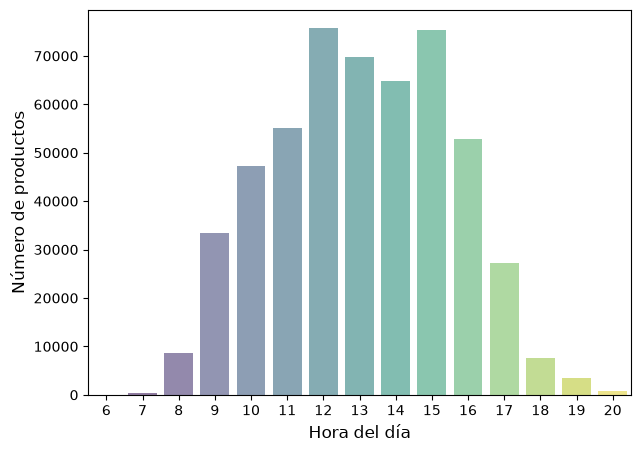

In [84]:
compras_positivas = consumer_data[
    consumer_data['IsProduct'] & (consumer_data['UnitPrice'] > 0) & (~consumer_data['IsCanceled']) & (consumer_data['Quantity'] > 0)
].copy()

plt.figure(figsize = (7,5))
sns.countplot(data=compras_positivas, x=compras_positivas['Hora'], hue = compras_positivas['Hora'], legend=False, palette = 'viridis', alpha=0.6)
plt.xlabel("Hora del día", fontsize=12)
plt.ylabel("Número de productos", fontsize=12)
plt.show()

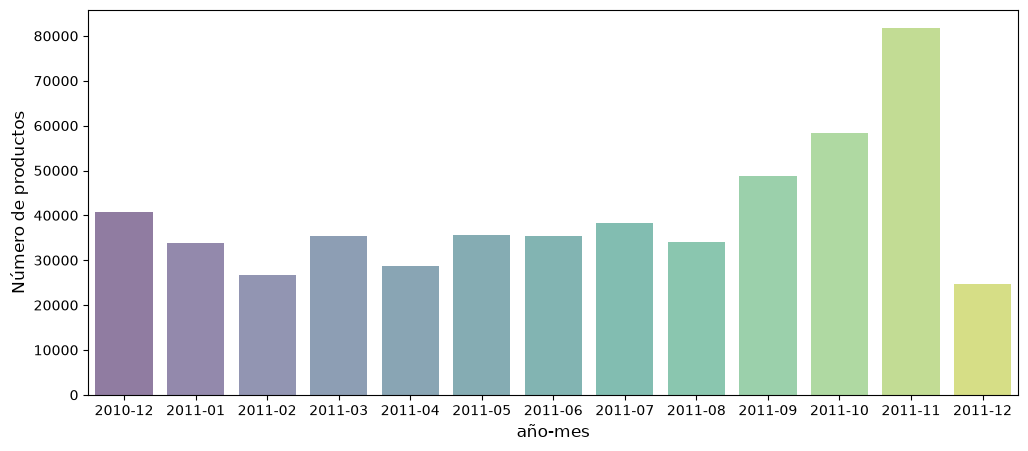

In [87]:
plt.figure(figsize = (12,5))
sns.countplot(data=compras_positivas, x=compras_positivas['Fecha'], hue = compras_positivas['Fecha'], legend=False, palette = 'viridis', alpha=0.6)
plt.xlabel("año-mes", fontsize=12)
plt.ylabel("Número de productos", fontsize=12)
plt.show()

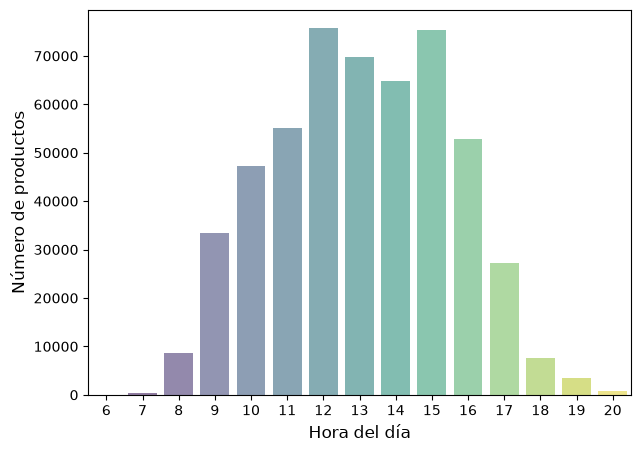

Text(0, 0.5, 'País')

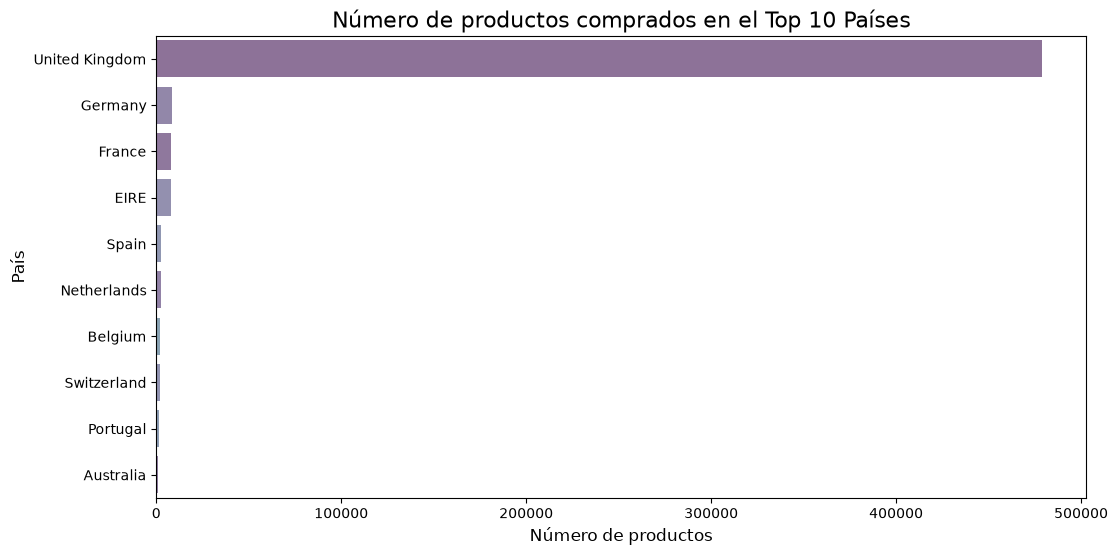

In [90]:
# crando la gráfica mostrando los departamentos más comprados
plt.figure(figsize=(12, 6))
sns.countplot(data=compras_positivas, y='Country', order=compras_positivas['Country'].value_counts().index[:10], hue='Country', legend = False,  palette='viridis', alpha=0.6)
plt.title('Número de productos comprados en el Top 10 Países', fontsize=16)
plt.xlabel('Número de productos', fontsize=12)
plt.ylabel('País', fontsize=12)

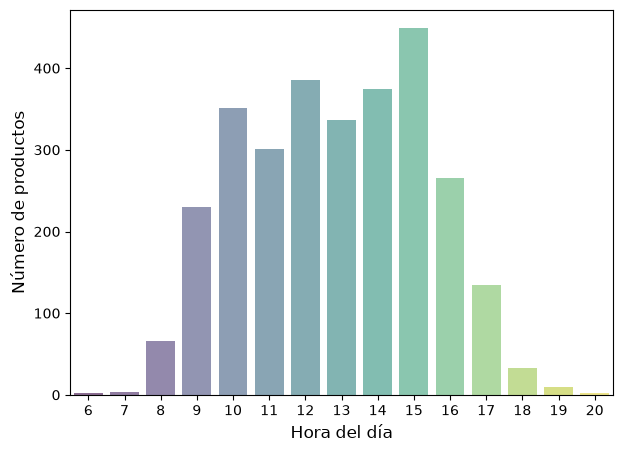

In [98]:
no_compras = consumer_data[
   ~consumer_data['IsProduct']
].copy()

plt.figure(figsize = (7,5))
sns.countplot(data=no_compras, x=no_compras['Hora'], hue = no_compras['Hora'], legend=False, palette = 'viridis', alpha=0.6)
plt.xlabel("Hora del día", fontsize=12)
plt.ylabel("Número de productos", fontsize=12)
plt.show()

Text(0, 0.5, 'País')

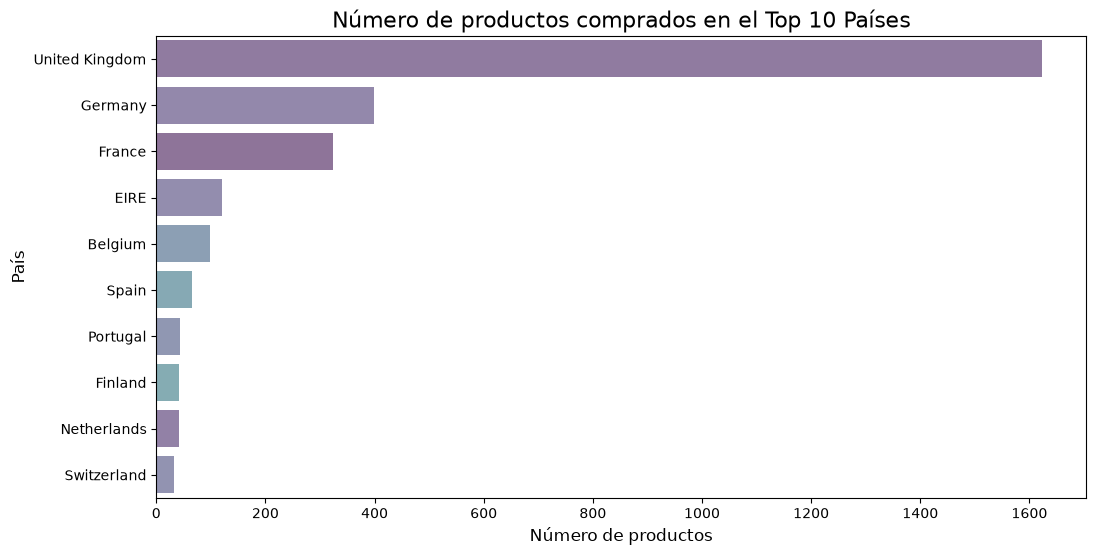

In [99]:
plt.figure(figsize=(12, 6))
sns.countplot(data=no_compras, y='Country', order=no_compras['Country'].value_counts().index[:10], hue='Country', legend = False,  palette='viridis', alpha=0.6)
plt.title('Número de productos comprados en el Top 10 Países', fontsize=16)
plt.xlabel('Número de productos', fontsize=12)
plt.ylabel('País', fontsize=12)

---
# Solución — Aprendizaje no supervisado

Con la base ya limpia (cancelaciones marcadas, códigos que no son productos identificados, `Total` calculado y duplicados eliminados), desarrollamos el análisis no supervisado que pide la actividad. La hoja de ruta sigue los 4 criterios de la rúbrica:

1. **Preparación y features** — base válida por cliente + **matriz RFM** (Recencia, Frecuencia, Monetario) y variables derivadas.
2. **Técnicas no supervisadas** — **Isolation Forest** (anomalías), **PCA** (reducción de dimensionalidad) y **K-Means** (clustering), con ajuste de parámetros.
3. **Interpretación y métricas** — selección de *k* por codo, **silueta** y **Calinski-Harabasz**; perfiles de clúster y visualizaciones.
4. **Negocio y conclusiones** — nombre y acción por segmento, y respuesta a las 3 preguntas guía.

## A. Preparación: de transacciones a clientes

### A.1 El problema de los `CustomerID` faltantes
El 25% de las filas no tiene `CustomerID`. Como el objetivo es **segmentar clientes**, un registro sin identificador no se puede asignar a nadie; por eso, para el análisis por cliente **excluimos esas filas** (no se imputan: inventar un cliente falsearía los segmentos). Nos quedamos además solo con **compras reales**: artículos (no cargos como POST/DOT), precio positivo, cantidad positiva y facturas **no canceladas**.

In [17]:
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.ensemble import IsolationForest
from sklearn.metrics import silhouette_score, calinski_harabasz_score, adjusted_rand_score
SEED = 42

# Base de COMPRAS validas para el analisis por cliente
compras = consumer_data[
    consumer_data['IsProduct'] & consumer_data['CustomerID'].notna() &
    (consumer_data['UnitPrice'] > 0) & (~consumer_data['IsCanceled']) & (consumer_data['Quantity'] > 0)
].copy()
compras['CustomerID'] = compras['CustomerID'].astype(int)

print(f'Filas tras limpieza base : {len(consumer_data):,}')
print(f'Compras validas          : {len(compras):,}')
print(f'Clientes identificados   : {compras["CustomerID"].nunique():,}')
print(f'Rango de fechas          : {compras["InvoiceDate"].min().date()} a {compras["InvoiceDate"].max().date()}')

Filas tras limpieza base : 536,641
Compras validas          : 391,150
Clientes identificados   : 4,334
Rango de fechas          : 2010-12-01 a 2011-12-09


### A.2 Exploración rápida antes de modelar
Dos vistas para entender el negocio: de dónde viene el dinero (países) y cómo se distribuye el valor de las líneas de compra.

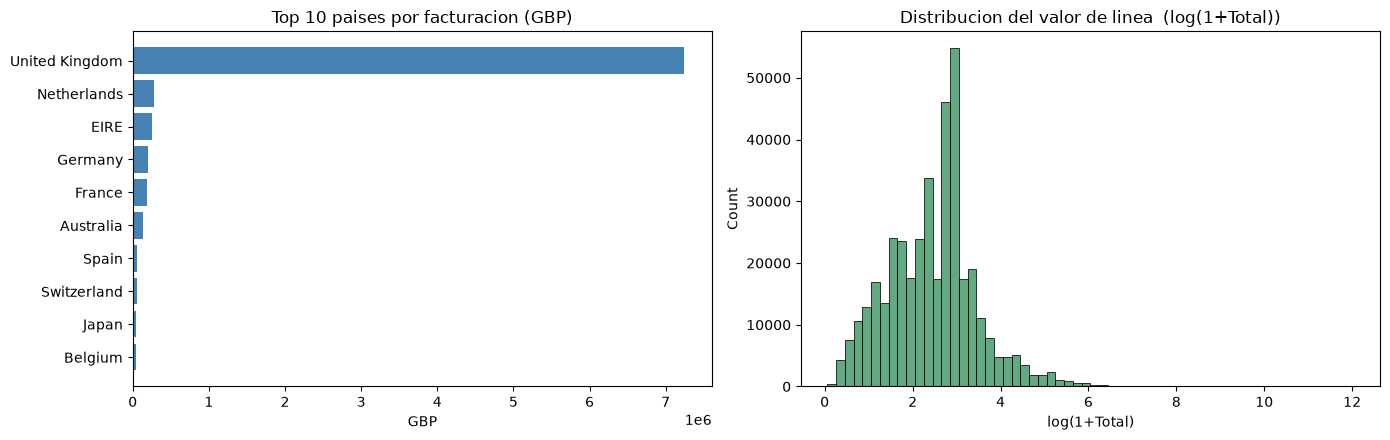

Reino Unido concentra el 82.9% de la facturacion.


In [18]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))

# Top 10 paises por facturacion
top_pais = compras.groupby('Country')['Total'].sum().sort_values(ascending=False).head(10)
ax[0].barh(top_pais.index[::-1], top_pais.values[::-1], color='steelblue')
ax[0].set_title('Top 10 paises por facturacion (GBP)'); ax[0].set_xlabel('GBP')

# Distribucion del valor de linea (log)
sns.histplot(np.log1p(compras['Total']), bins=60, ax=ax[1], color='seagreen')
ax[1].set_title('Distribucion del valor de linea  (log(1+Total))'); ax[1].set_xlabel('log(1+Total)')
plt.tight_layout(); plt.show()

print('Reino Unido concentra el %.1f%% de la facturacion.' % (100*top_pais.iloc[0]/compras['Total'].sum()))

### A.3 Ingeniería de características: la matriz RFM
La regla de oro del análisis: **una fila = un cliente**. Construimos las tres variables clásicas de valor de cliente (**RFM**) más algunas derivadas:

- **Recencia**: días desde su última compra (menor = más activo).
- **Frecuencia**: número de facturas distintas.
- **Monetario**: gasto total.
- **Ticket promedio**, **unidades** y **productos distintos** como refuerzo.

In [19]:
REF = compras['InvoiceDate'].max() + pd.Timedelta(days=1)   # fecha de referencia para la recencia
g = compras.groupby('CustomerID')
clientes_df = pd.DataFrame({
    'recencia':            (REF - g['InvoiceDate'].max()).dt.days,
    'frecuencia':          g['InvoiceNo'].nunique(),
    'monetario':           g['Total'].sum(),
    'ticket_promedio':     g['Total'].sum() / g['InvoiceNo'].nunique(),
    'unidades':            g['Quantity'].sum(),
    'productos_distintos': g['StockCode'].nunique(),
})
print('Matriz de clientes:', clientes_df.shape)
clientes_df.describe(percentiles=[.25, .5, .75, .9, .99]).round(1)

Matriz de clientes: (4334, 6)


,recencia,frecuencia,monetario,ticket_promedio,unidades,productos_distintos
count,4334.0,4334.0,4334.0,4334.0,4334.0,4334.0
mean,92.7,4.2,2016.0,415.5,1186.4,61.4
std,100.2,7.6,8903.7,1800.9,5040.6,85.3
min,1.0,1.0,3.8,3.8,1.0,1.0
25%,18.0,1.0,304.2,177.2,159.2,16.0
50%,51.0,2.0,662.6,289.6,377.5,35.0
75%,143.0,5.0,1631.6,423.4,989.8,77.0
90%,263.0,9.0,3560.1,657.8,2109.7,142.7
99%,369.0,30.0,18715.3,2023.8,10887.8,353.7
max,374.0,206.0,279138.0,84236.2,196844.0,1785.0


**Lectura.** El **cliente mediano** compró por última vez hace ~51 días, hizo 2 pedidos y gastó ~£663; pero la media (£2.016) es 3× la mediana: hay **colas muy largas** (mayoristas que gastan cientos de miles). Esas colas son la razón por la que más adelante (a) escalamos con logaritmo y (b) separamos los atípicos antes de agrupar.

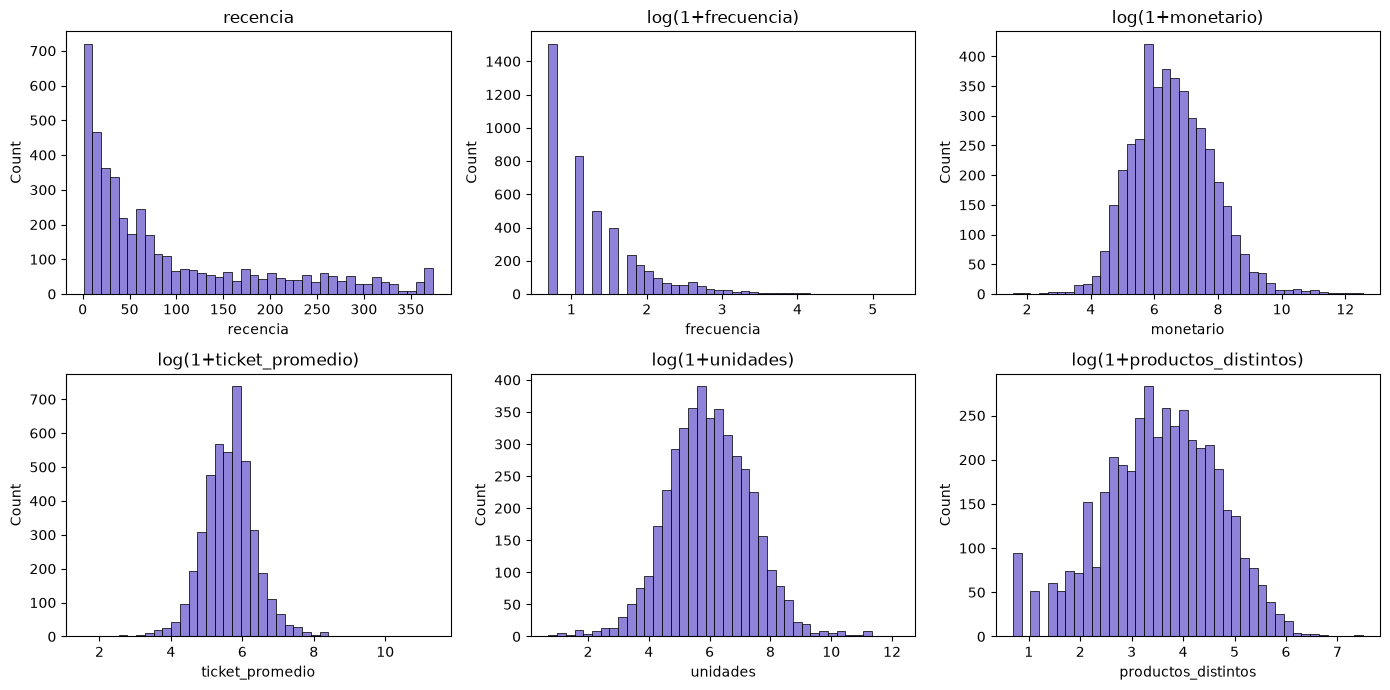

In [20]:
# Distribucion de las 6 features (escala log en las de cola larga)
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), clientes_df.columns):
    serie = clientes_df[col]
    logy = col != 'recencia'
    sns.histplot(np.log1p(serie) if logy else serie, bins=40, ax=ax, color='slateblue')
    ax.set_title(('log(1+' + col + ')') if logy else col)
plt.tight_layout(); plt.show()

## B. Detección de anomalías con Isolation Forest

Antes de segmentar conviene detectar los **atípicos**, porque un puñado de mayoristas gigantes deforma cualquier clustering (K-Means los pondría en su propio grupo o desplazaría los centroides). **Isolation Forest** es ideal: aísla puntos raros con árboles aleatorios, no asume forma de los datos y funciona bien en alta dimensión. El parámetro clave es `contamination` (fracción esperada de atípicos); usamos **5%** a nivel cliente.

Clientes atipicos: 217 (5.0%)
Concentran el 39.5% de la facturacion total.


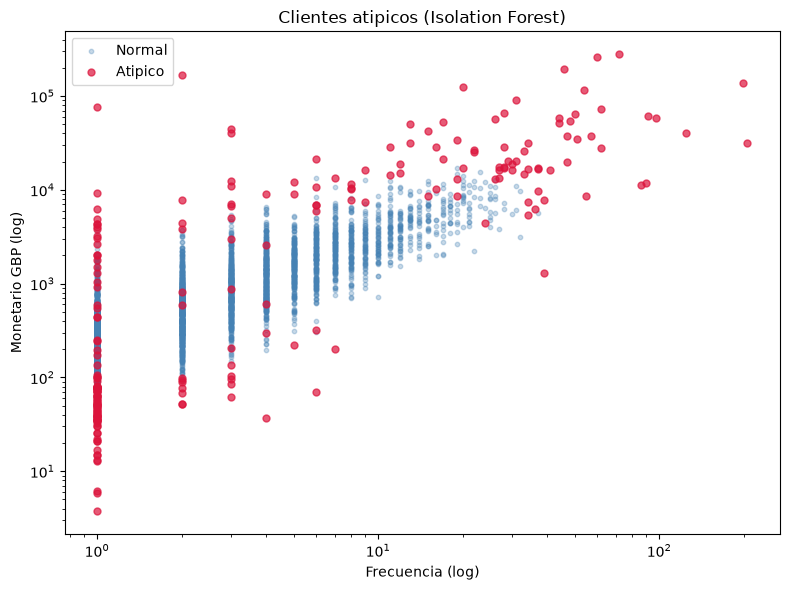

In [21]:
# Escalado (log en las de cola larga) para que la distancia no la dominen las £
LOG = ['frecuencia', 'monetario', 'ticket_promedio', 'unidades', 'productos_distintos']
X_log = clientes_df.copy()
for c in LOG:
    X_log[c] = np.log1p(X_log[c])
X_esc = StandardScaler().fit_transform(X_log)

iso_cli = IsolationForest(n_estimators=300, contamination=0.05, random_state=SEED)
clientes_df['anomalo'] = (iso_cli.fit_predict(X_esc) == -1)

n_a = clientes_df['anomalo'].sum()
pct_mon = 100 * clientes_df.loc[clientes_df['anomalo'], 'monetario'].sum() / clientes_df['monetario'].sum()
print(f'Clientes atipicos: {n_a} ({100*n_a/len(clientes_df):.1f}%)')
print(f'Concentran el {pct_mon:.1f}% de la facturacion total.')

fig, ax = plt.subplots(figsize=(8, 6))
normal = clientes_df[~clientes_df['anomalo']]; anom = clientes_df[clientes_df['anomalo']]
ax.scatter(normal['frecuencia'], normal['monetario'], s=10, alpha=0.3, label='Normal', color='steelblue')
ax.scatter(anom['frecuencia'], anom['monetario'], s=25, alpha=0.7, label='Atipico', color='crimson')
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel('Frecuencia (log)'); ax.set_ylabel('Monetario GBP (log)')
ax.set_title('Clientes atipicos (Isolation Forest)'); ax.legend()
plt.tight_layout(); plt.show()

**Interpretación (responde: ¿hay clientes atípicos?).** Sí. Isolation Forest marca **~217 clientes (5%)** que, siendo una minoría, **concentran ~40% de toda la facturación**: son los **grandes mayoristas** (frecuencia y gasto extremos). No son errores, son un segmento real de altísimo valor, pero **los apartamos** para que el clustering describa al cliente típico; se analizan por separado como cuentas VIP.

### B.2 Anomalías a nivel transacción
La otra pregunta guía es sobre **transacciones** anómalas. Cambiamos la unidad de análisis a la **factura** (importe, nº de líneas, unidades, precio medio) y aplicamos Isolation Forest con `contamination=2%`.

In [22]:
gf = compras.groupby('InvoiceNo')
facturas = pd.DataFrame({
    'importe':  gf['Total'].sum(),
    'lineas':   gf['StockCode'].nunique(),
    'unidades': gf['Quantity'].sum(),
})
facturas['precio_medio'] = facturas['importe'] / facturas['unidades']
Xf = StandardScaler().fit_transform(np.log1p(facturas.clip(lower=0)))

iso_fac = IsolationForest(n_estimators=300, contamination=0.02, random_state=SEED)
facturas['anomala'] = (iso_fac.fit_predict(Xf) == -1)
print(f'Facturas anomalas: {facturas["anomala"].sum()} ({100*facturas["anomala"].mean():.1f}%)')
print('Importe medio  normal: GBP %.0f   |   anomalo: GBP %.0f' % (
      facturas.loc[~facturas['anomala'],'importe'].mean(), facturas.loc[facturas['anomala'],'importe'].mean()))
print('\nEjemplos de facturas anomalas (mayor importe):')
facturas[facturas['anomala']].nlargest(5, 'importe').round(0)

Facturas anomalas: 366 (2.0%)
Importe medio  normal: GBP 414   |   anomalo: GBP 3449

Ejemplos de facturas anomalas (mayor importe):


,importe,lineas,unidades,precio_medio,anomala
InvoiceNo,,,,,
581483,168470.0,1,80995,2.0,True
541431,77184.0,1,74215,1.0,True
556444,38970.0,1,60,650.0,True
567423,31698.0,12,12572,3.0,True
556917,22776.0,138,15049,2.0,True


**Interpretación (responde: ¿hay transacciones anómalas?).** Sí: **~366 facturas (2%)** con importe medio **£3.449 vs £414** de una factura normal (8×). Las más extremas son **pedidos mayoristas gigantescos** (facturas 581483 y 541431, con decenas de miles de unidades de un solo producto). Son operaciones legítimas pero excepcionales que conviene revisar aparte (riesgo, logística, crédito).

## C. Escalamiento y PCA (sobre la base depurada)

Trabajamos ahora **sin los clientes atípicos**. Reescalamos y aplicamos **PCA** para (a) ver cuántas dimensiones reales hay y (b) alimentar la validación visual. Las 12→6 features están muy correlacionadas (frecuencia, monetario, unidades, productos crecen juntas), así que PCA debería comprimir mucho.

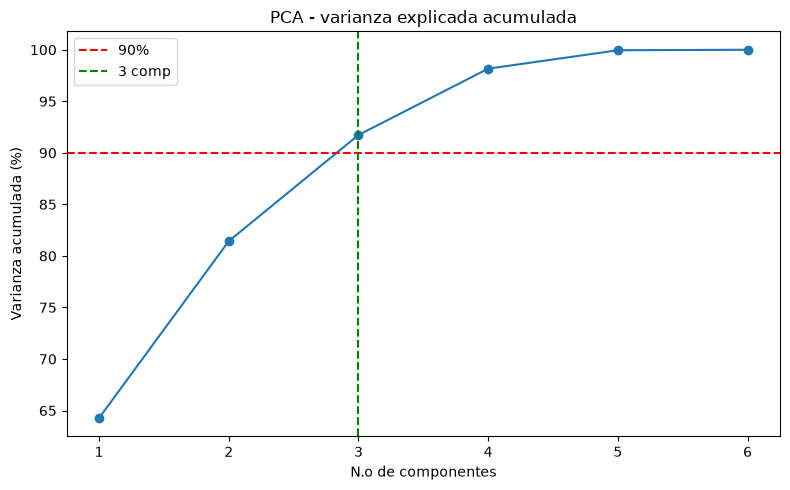

3 componentes explican el 91.7% de la varianza.


In [23]:
clean = clientes_df[~clientes_df['anomalo']].copy()
X_clean = clean[['recencia'] + LOG].copy()
for c in LOG:
    X_clean[c] = np.log1p(X_clean[c])
X_clean_esc = StandardScaler().fit_transform(X_clean)

pca_full = PCA(random_state=SEED).fit(X_clean_esc)
evr = np.cumsum(pca_full.explained_variance_ratio_)
n_comp = int(np.argmax(evr >= 0.90) + 1)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(range(1, len(evr)+1), 100*evr, marker='o')
ax.axhline(90, color='red', ls='--', label='90%'); ax.axvline(n_comp, color='green', ls='--', label=f'{n_comp} comp')
ax.set_xlabel('N.o de componentes'); ax.set_ylabel('Varianza acumulada (%)')
ax.set_title('PCA - varianza explicada acumulada'); ax.legend()
plt.tight_layout(); plt.show()
print(f'{n_comp} componentes explican el {100*evr[n_comp-1]:.1f}% de la varianza.')

X_pca = PCA(n_components=n_comp, random_state=SEED).fit_transform(X_clean_esc)

**Lectura.** Con **3 componentes se retiene ~91%** de la varianza: de 6 variables a 3 dimensiones sin perder casi nada, porque las features de "intensidad de compra" (frecuencia, monetario, unidades, productos) son casi la misma información. Esto simplifica y da robustez al clustering.

## D. Selección del número de clústeres

No hay un *k* "verdadero"; se decide con criterios que a veces discrepan (y esa discrepancia informa). Usamos tres: **codo** (inercia), **silueta** (separación, ↑ mejor) y **Calinski-Harabasz** (↑ mejor).

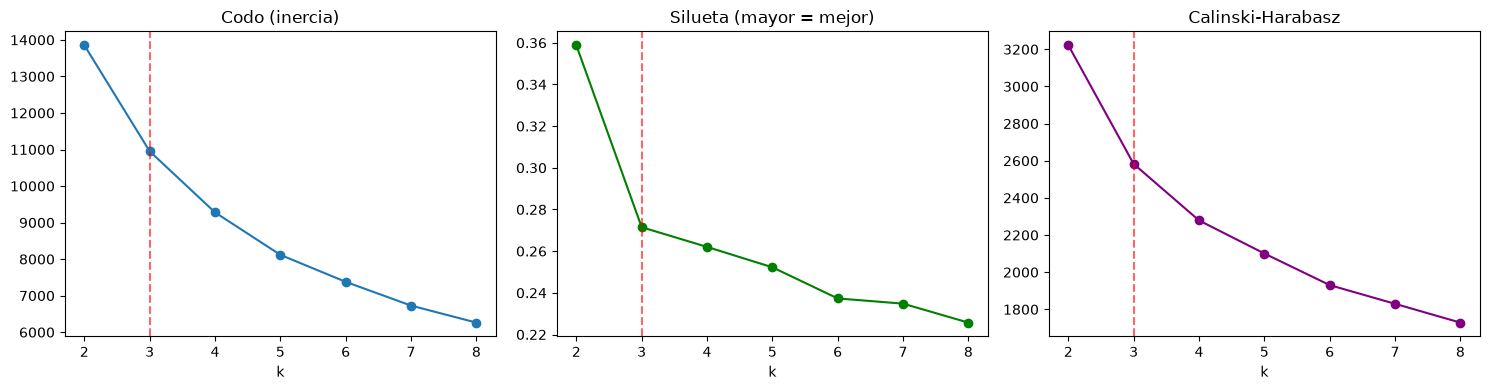

k | inercia | silueta | CH
2 |    13854 | 0.359 |     3222
3 |    10952 | 0.271 |     2583
4 |     9279 | 0.262 |     2279
5 |     8117 | 0.252 |     2101
6 |     7378 | 0.237 |     1930
7 |     6729 | 0.235 |     1830
8 |     6262 | 0.226 |     1729


In [24]:
ks = range(2, 9)
inercia, silueta, ch = [], [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X_clean_esc)
    inercia.append(km.inertia_)
    silueta.append(silhouette_score(X_clean_esc, km.labels_))
    ch.append(calinski_harabasz_score(X_clean_esc, km.labels_))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(list(ks), inercia, marker='o'); ax[0].set_title('Codo (inercia)'); ax[0].set_xlabel('k')
ax[1].plot(list(ks), silueta, marker='o', color='green'); ax[1].set_title('Silueta (mayor = mejor)'); ax[1].set_xlabel('k')
ax[2].plot(list(ks), ch, marker='o', color='purple'); ax[2].set_title('Calinski-Harabasz'); ax[2].set_xlabel('k')
for a in ax: a.axvline(3, color='red', ls='--', alpha=0.6)
plt.tight_layout(); plt.show()

print('k | inercia | silueta | CH')
for k, i, s, c in zip(ks, inercia, silueta, ch):
    print(f'{k} | {i:8.0f} | {s:.3f} | {c:8.0f}')

**Lectura y decisión.** La silueta y el Calinski-Harabasz son máximos en **k=2**, pero k=2 solo separaría "clientes grandes vs pequeños": poco accionable. El **codo se dobla en k=3**, y k=3 produce la segmentación **RFM clásica de 3 niveles** (bajo / medio / alto valor), mucho más útil para el negocio con una pérdida mínima de silueta. **Elegimos k=3**: es el equilibrio entre calidad estadística y valor accionable (la rúbrica premia justificar esta elección).

## E. Clustering: K-Means (y comparación)

Aplicamos **K-Means con k=3** y lo comparamos con **clustering jerárquico (Agglomerative)** para verificar que la partición es estable y no un artefacto de un solo algoritmo.

In [25]:
K = 3
km = KMeans(n_clusters=K, n_init=20, random_state=SEED).fit(X_clean_esc)
clean['Cluster'] = km.labels_

# comparacion con jerarquico
agg = AgglomerativeClustering(n_clusters=K).fit_predict(X_clean_esc)
ari = adjusted_rand_score(km.labels_, agg)

print(f'K-Means k={K}:')
print(f'  Silueta            : {silhouette_score(X_clean_esc, km.labels_):.3f}')
print(f'  Calinski-Harabasz  : {calinski_harabasz_score(X_clean_esc, km.labels_):.0f}')
print(f'  Acuerdo con jerarquico (ARI): {ari:.3f}  (1 = identico)')
print('\nTamano de cada cluster:')
print(clean['Cluster'].value_counts().sort_index())

K-Means k=3:
  Silueta            : 0.272
  Calinski-Harabasz  : 2583
  Acuerdo con jerarquico (ARI): 0.574  (1 = identico)

Tamano de cada cluster:
Cluster
0    1734
1    1265
2    1118
Name: count, dtype: int64


**Métricas.** La silueta (~0.27) es moderada —normal en datos de clientes, que forman un continuo más que islas separadas— y el **acuerdo razonable con el clustering jerárquico (ARI ≈ 0.57)** indica que los 3 grupos no son un capricho de K-Means, sino una estructura reconocible por más de un algoritmo.

## F. Interpretación: perfil de cada segmento

Un clúster sin nombre no sirve. Perfilamos cada grupo con las **medias en las variables originales** (no escaladas) y lo validamos visualmente.

In [26]:
perfil = clean.groupby('Cluster').agg(
    n_clientes=('monetario', 'size'),
    recencia=('recencia', 'mean'),
    frecuencia=('frecuencia', 'mean'),
    monetario=('monetario', 'mean'),
    ticket_promedio=('ticket_promedio', 'mean'),
    productos_distintos=('productos_distintos', 'mean'),
).round(1)
perfil['%_clientes'] = (100 * perfil['n_clientes'] / len(clean)).round(1)
perfil

,n_clientes,recencia,frecuencia,monetario,ticket_promedio,productos_distintos,%_clientes
Cluster,,,,,,,
0,1734,71.0,2.5,773.8,382.5,45.3,42.1
1,1265,173.2,1.4,243.7,194.3,16.2,30.7
2,1118,29.7,8.2,3248.4,453.5,127.8,27.2


C:\Users\victor.novoa\AppData\Local\Temp\ipykernel_28116\676838530.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=clean, x='Cluster', y='monetario', ax=axes[1],


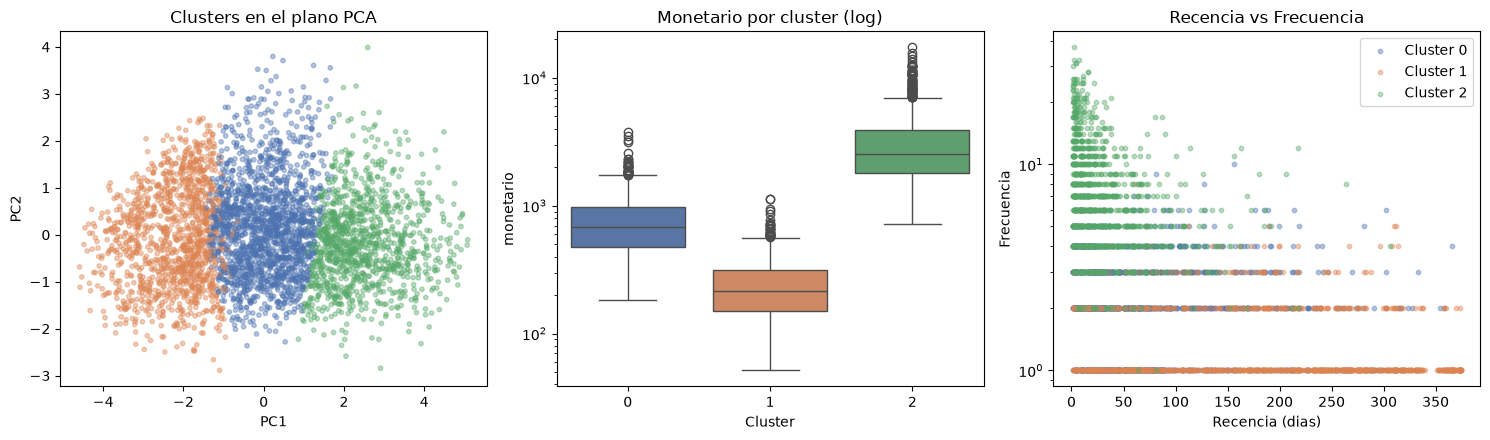

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
colores = {0: '#4C72B0', 1: '#DD8452', 2: '#55A868'}
cvec = clean['Cluster'].map(colores)

# 1) Dispersion en el plano PCA
axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=cvec, s=10, alpha=0.4)
axes[0].set_title('Clusters en el plano PCA'); axes[0].set_xlabel('PC1'); axes[0].set_ylabel('PC2')

# 2) Monetario por cluster (log)
sns.boxplot(data=clean, x='Cluster', y='monetario', ax=axes[1],
            palette=[colores[k] for k in sorted(clean['Cluster'].unique())])
axes[1].set_yscale('log'); axes[1].set_title('Monetario por cluster (log)')

# 3) Recencia vs Frecuencia
for cl in sorted(clean['Cluster'].unique()):
    sub = clean[clean['Cluster'] == cl]
    axes[2].scatter(sub['recencia'], sub['frecuencia'], s=10, alpha=0.4, color=colores[cl], label=f'Cluster {cl}')
axes[2].set_xlabel('Recencia (dias)'); axes[2].set_ylabel('Frecuencia'); axes[2].set_yscale('log')
axes[2].set_title('Recencia vs Frecuencia'); axes[2].legend()
plt.tight_layout(); plt.show()

**Los 3 segmentos (identifícalos en tu corrida por su perfil):**

| Segmento | % clientes | Recencia | Frecuencia | Monetario | Lectura |
|---|---|---|---|---|---|
| **Leales / alto valor** | ~27% | baja (~30 d) | alta (~8) | ~£3.200 | compran seguido, reciente y mucho — el motor del negocio |
| **Ocasionales / valor medio** | ~42% | media (~70 d) | media (~2.4) | ~£770 | el grueso; potencial de crecer |
| **Dormidos / bajo valor** | ~31% | alta (~170 d) | baja (~1.4) | ~£240 | compraron poco y hace mucho — riesgo de fuga |

Los tres ejes RFM separan limpiamente a los grupos: el segmento leal es bajo en recencia y alto en frecuencia/monetario; el dormido es lo opuesto.

## G. Conclusiones de negocio y respuesta a las preguntas guía

### Respuestas a las preguntas de orientación

**PG1 — ¿Se pueden segmentar los clientes según sus transacciones y gasto?**
**Sí.** Con la matriz RFM + K-Means (k=3, justificado con codo/silueta/CH y validado con clustering jerárquico) emergen **tres segmentos claros y accionables**: *Leales/alto valor* (~27%), *Ocasionales/medio* (~42%) y *Dormidos/bajo valor* (~31%). La partición es coherente entre algoritmos (ARI ≈ 0.57 con el jerárquico) y con la teoría RFM.

**PG2 — ¿Se pueden identificar transacciones anómalas?**
**Sí.** Isolation Forest a nivel factura marca **~366 transacciones (2%)** con importe medio 8× el normal (£3.449 vs £414); las extremas son pedidos mayoristas gigantescos (facturas 581483, 541431). Son legítimas pero excepcionales y merecen control aparte.

**PG3 — ¿Se pueden identificar clientes atípicos?**
**Sí.** Isolation Forest a nivel cliente marca **~217 clientes (5%)** que concentran **~40% de la facturación**: los grandes mayoristas. Constituyen un segmento VIP que se gestiona por separado.

### Acciones por segmento
- **Leales / alto valor** → programa de fidelización, ventas cruzadas, atención prioritaria; proteger este núcleo.
- **Ocasionales / medio** → campañas para aumentar frecuencia (recomendaciones, ofertas por recompra).
- **Dormidos / bajo valor** → reactivación (email win-back, descuento de regreso); si no responden, no invertir más.
- **Mayoristas atípicos** → cuentas gestionadas, condiciones de crédito y logística especiales.

### Cumplimiento de la rúbrica
| Criterio | Dónde se cumple |
|---|---|
| **1. Preparación y exploración** | Limpieza (cancelaciones, no-productos, duplicados, faltantes) + EDA + **matriz RFM** con features derivadas (Parte A). |
| **2. Técnicas no supervisadas** | **Isolation Forest** (B), **PCA** (C) y **K-Means** con ajuste de `k`, `contamination`, `n_init` (D-E); comparación con jerárquico. |
| **3. Interpretación y métricas** | **Silueta**, **Calinski-Harabasz**, **ARI**, varianza PCA; perfiles y visualizaciones (D-F). |
| **4. Negocio y conclusiones** | Segmentos con nombre y acción + respuesta a PG1/PG2/PG3 (G). |

> **Nota sobre el entregable.** La guía pide un **informe en PDF sin código**; este notebook es el análisis reproducible del que se extrae ese informe (las lecturas en negrita de cada sección son el texto del informe).